# Interactive 3D Manifold Trajectory and Effectomes

Explore a consecutive manifold window with rounded temporal paths and synchronized active/mean effectome panels. Start-step and segment-count sliders choose the visible range; Previous and Next move by the selected range size.
The rounded paths use endpoint-preserving centripetal Catmull--Rom interpolation inspired by the BunDLe trajectory presentation. Every observed manifold point is retained. Curves stop at recording gaps, bad-frame boundaries, and cross-fit fold boundaries, so smoothing never bridges a declared discontinuity.
The visualization is descriptive. A smooth display curve does not add observations, establish continuous-time dynamics, or support causal interpretation.
Progress: long stages print checkpoint-aware timing; iterative stages also display live progress bars. Reused, failed, running, and missing checkpoints are reported explicitly.

Environment: select the project Python 3.14 `.venv` kernel. Install the locked packages with `uv sync --python 3.14 --locked --extra dev --extra csl --extra community --extra notebooks` from the repository root. The setup cell checks installed package versions; no upstream repository clone is required. Stored outputs may predate the backend migration; rerun the notebook to produce results with the current backend.


In [1]:
import sys
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

try:
    _REPOSITORY_ROOT = next(
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "notebooks" / "_shared.py").is_file()
    )
except StopIteration as error:
    raise RuntimeError(
        "Could not locate the effectome repository from the notebook working directory"
    ) from error
sys.path[:0] = [
    path
    for path in (str(_REPOSITORY_ROOT / "src"), str(_REPOSITORY_ROOT))
    if path not in sys.path
]

if sys.version_info[:2] != (3, 14):
    raise RuntimeError(
        "Select the project Python 3.14 .venv kernel before running this notebook. "
        f"Current interpreter: {sys.executable}"
    )
_BACKEND_DISTRIBUTIONS = ("fastcgc", "tigramite", "scikit-learn", "kmedoids", "igraph", "leidenalg")
try:
    _BACKEND_VERSIONS = {name: version(name) for name in _BACKEND_DISTRIBUTIONS}
except PackageNotFoundError as error:
    raise RuntimeError(
        "The notebook kernel is missing a required installed backend. Run "
        "uv sync --python 3.14 --locked --extra dev --extra csl --extra community --extra notebooks "
        "from the repository root, then restart the project .venv kernel."
    ) from error
print("Notebook interpreter:", sys.executable)
print("Installed backends:", _BACKEND_VERSIONS)


Notebook interpreter: /Users/sadiqadedayo/Documents/projects/effectome-to-behavior/effectome-to-behavior/.venv/bin/python
Installed backends: {'fastcgc': '0.1.0', 'tigramite': '5.2.10.1', 'scikit-learn': '1.9.0', 'kmedoids': '0.5.5', 'igraph': '1.0.0', 'leidenalg': '0.12.0'}


In [2]:
import importlib
import sys

from IPython import get_ipython

shell = get_ipython()
if shell is None:
    raise RuntimeError("Run this file as a Jupyter notebook")

# Prefer an embedded widget when ipympl is available. The project adds no new
# dependency for this visualization, so a local native window is the default
# fallback (macOS first, then Tk, then a noninteractive inline figure).
backend_candidates = ["widget"]
if sys.platform == "darwin":
    backend_candidates.append("osx")
else:
    backend_candidates.append("tk")
backend_candidates.append("inline")
backend_errors = {}
for backend_name in backend_candidates:
    try:
        shell.run_line_magic("matplotlib", backend_name)
        INTERACTIVE_BACKEND = backend_name
        break
    except (ImportError, ModuleNotFoundError, RuntimeError) as error:
        backend_errors[backend_name] = str(error)
else:
    raise RuntimeError(f"No Matplotlib notebook backend is available: {backend_errors}")

shared = importlib.import_module("notebooks._shared")
visualization = importlib.import_module("scripts.plot_manifold_trajectory")
PROJECT_ROOT = shared.PROJECT_ROOT
make_run = shared.make_run
print_notebook_header = shared.print_notebook_header
print_stage_status = shared.print_stage_status
TrajectoryExplorer = visualization.TrajectoryExplorer
load_trajectory_data = visualization.load_trajectory_data

OUTPUT_BASE = PROJECT_ROOT / "outputs"
DATASET_OUTPUT_ID = "bundle-net-c-elegans"
RECORDING_ID = "bundle-net-worm-0"
RUN_ID = "reference"
METHOD = "cgc"
COLOR_BY = "motif"  # "motif", "graph", or "hmm"
BEHAVIOR_KEY = "motif"

# Initial control values. The sliders can change all three after this cell runs.
START_STEP = 0
SEGMENTS_PER_VIEW = 25
ACTIVE_EFFECTOME_STEP = START_STEP
CURVE_SAMPLES_PER_SEGMENT = 20
ARROW_STRIDE = 1

OUTPUT_ROOT = OUTPUT_BASE / "analysis" / DATASET_OUTPUT_ID / RECORDING_ID
RUN_ROOT = OUTPUT_ROOT / RUN_ID
run = make_run(OUTPUT_ROOT, RUN_ID, METHOD)
expected = ["connectivity", "manifold"]
if COLOR_BY == "graph":
    expected.append("graph_states")
elif COLOR_BY == "hmm":
    expected.append("probabilistic_states")
print_notebook_header(
    run,
    title="Interactive 3D manifold trajectory",
    expected_stages=expected,
    force=False,
)
print("Matplotlib backend:", INTERACTIVE_BACKEND)


/Users/sadiqadedayo/Documents/projects/effectome-to-behavior/effectome-to-behavior/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Interactive 3D manifold trajectory
run_id=reference method=cgc
run_dir=/Users/sadiqadedayo/Documents/projects/effectome-to-behavior/effectome-to-behavior/outputs/analysis/bundle-net-c-elegans/bundle-net-worm-0/reference/cgc
resume mode: FORCE=False, matching completed checkpoints will be reused
Rerun interrupted notebooks from the top; completed stages resume from checkpoints.
Stage status for reference/cgc:
  - candidate_drivers: running (signature=fd97634a32, artifact=no)
  - community: completed (signature=5e628d8394, artifact=yes)
  - connectivity: completed (signature=867a8d53f5, artifact=yes)
  - connectivity.chunk-00000: completed (signature=1b91e06b3b, artifact=yes)
  - connectivity.chunk-00001: completed (signature=1c728c3716, artifact=yes)
  - connectivity.chunk-00002: completed (signature=3b9a51a36a, artifact=yes)
  - connectivity.chunk-00003: completed (signature=fc4c5d2507, artifact=yes)
  - connectivity.chunk-00004: completed (signature=5d38173532, artifact=yes)
  - conne

In [3]:
trajectory = load_trajectory_data(
    RUN_ROOT,
    method=METHOD,
    color_by=COLOR_BY,
    behavior_key=BEHAVIOR_KEY,
)
print(
    f"Loaded {trajectory.embedding.shape[0]} manifold steps, "
    f"{trajectory.effectomes.shape[1]} effectome rows, "
    f"and {trajectory.valid_steps.sum()} valid temporal joins"
)
print_stage_status(run)


Loaded 186 manifold steps, 109 effectome rows, and 181 valid temporal joins
Stage status for reference/cgc:
  - candidate_drivers: running (signature=fd97634a32, artifact=no)
  - community: completed (signature=5e628d8394, artifact=yes)
  - connectivity: completed (signature=867a8d53f5, artifact=yes)
  - connectivity.chunk-00000: completed (signature=1b91e06b3b, artifact=yes)
  - connectivity.chunk-00001: completed (signature=1c728c3716, artifact=yes)
  - connectivity.chunk-00002: completed (signature=3b9a51a36a, artifact=yes)
  - connectivity.chunk-00003: completed (signature=fc4c5d2507, artifact=yes)
  - connectivity.chunk-00004: completed (signature=5d38173532, artifact=yes)
  - connectivity.chunk-00005: completed (signature=d6e22c9982, artifact=yes)
  - connectivity.chunk-00006: completed (signature=a0d18987bf, artifact=yes)
  - connectivity.chunk-00007: completed (signature=6184720ad9, artifact=yes)
  - connectivity.chunk-00008: completed (signature=0aa699b7c0, artifact=yes)
  - c

## Explore consecutive segments

Use **Start step** and **Segments** to select the consecutive trajectory window. **Previous** and **Next** move by the current segment count. **Effectome step** selects the black-diamond manifold point and its matching matrix; the lower matrix is the mean across all points in the visible window.

Drag the 3D axis to rotate it and scroll to zoom. If the backend falls back to `inline`, edit the initial values above and rerun this cell; sliders need an interactive Matplotlib backend.


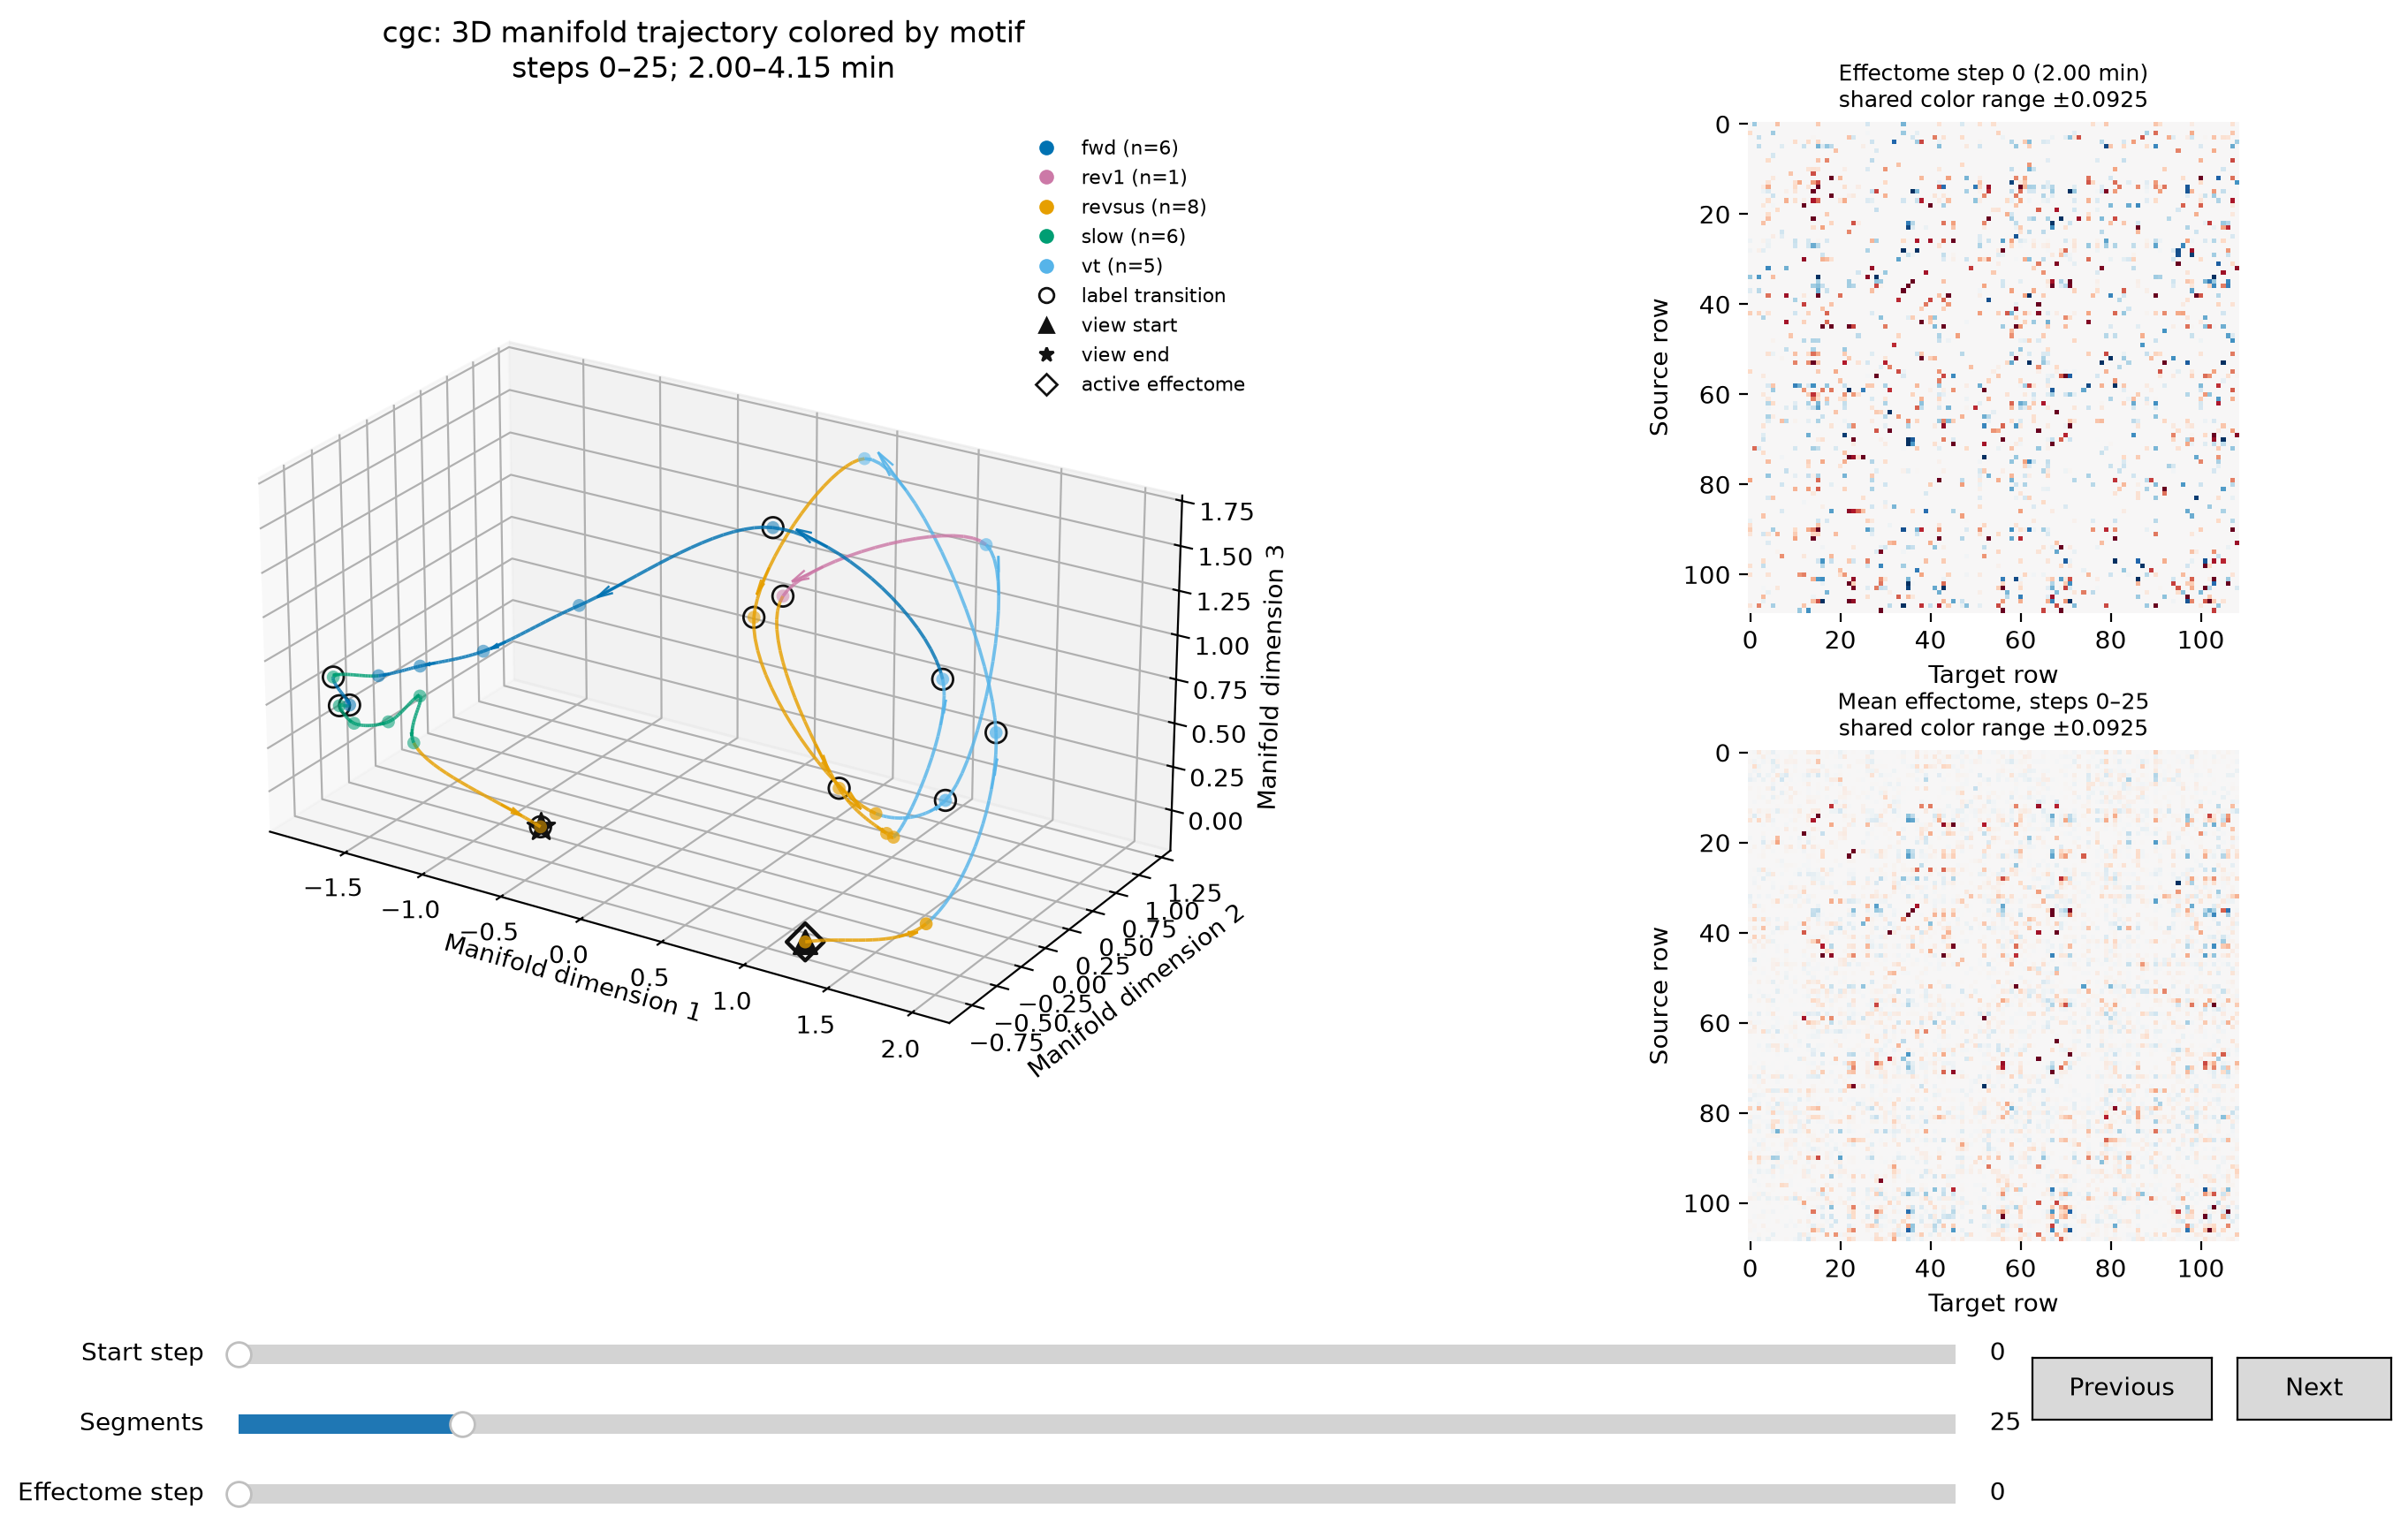

In [4]:
explorer = TrajectoryExplorer(
    trajectory,
    start_step=START_STEP,
    segment_count=SEGMENTS_PER_VIEW,
    active_step=ACTIVE_EFFECTOME_STEP,
    curve_samples=CURVE_SAMPLES_PER_SEGMENT,
    arrow_stride=ARROW_STRIDE,
)
explorer.figure


## Export the current selection

Move the controls to the desired window before running this cell. The PNG and GIF preserve the active and mean effectome panels. Adjust frame count, rate, and DPI as needed.


In [5]:
EXPORT_DIRECTORY = PROJECT_ROOT / "outputs" / "analysis-output" / "manifold-3d"
start, count, active = explorer.selection
stem = f"manifold-3d-{METHOD}-{COLOR_BY}-steps-{start}-{start + count}-active-{active}"
png_path = explorer.save_png(EXPORT_DIRECTORY / f"{stem}.png", dpi=160)
gif_path = explorer.save_gif(
    EXPORT_DIRECTORY / f"{stem}.gif",
    frames=72,
    fps=12,
    dpi=110,
)
print("Saved:", png_path)
print("Saved:", gif_path)


Saved: /Users/sadiqadedayo/Documents/projects/effectome-to-behavior/effectome-to-behavior/outputs/analysis-output/manifold-3d/manifold-3d-cgc-motif-steps-0-25-active-0.png
Saved: /Users/sadiqadedayo/Documents/projects/effectome-to-behavior/effectome-to-behavior/outputs/analysis-output/manifold-3d/manifold-3d-cgc-motif-steps-0-25-active-0.gif
